# Task 1

# Теория кластеризации

## 1. Инициализация центроидов для K-means

K-means — итеративный алгоритм(точка приписывается к кластеру -> подсчет центроида как среднее точек до того момента пока центроиды не останутся на месте), который минимизирует distortion (сумму квадратов расстояний от точек до их центроидов). Результат сильно зависит от начального выбора центроидов, поэтому инициализация крайне важна

### Forgy initialization
Центроиды выбираются как k случайных точек из обучающей выборки (без повторений).

**Плюсы:**
- Простота реализации.
- Центроиды сразу лежат в области данных, что ускоряет сходимость на «хороших» данных.
- Хорошо работает, когда кластеры компактны и далеко друг от друга.

**Минусы:**
- Высокая дисперсия результата: разные запуски дают разные кластеры.
- Может выбрать несколько центроидов в одном и том же реальном кластере, оставив другой кластер без представителя.
- Чувствителен к выбросам: если случайно выбранная точка — выброс, целый кластер «уедет» в сторону.

### Random Partition
Каждой точке случайно присваивается номер кластера от 1 до k, затем центроиды вычисляются как средние точки каждого кластера.

**Плюсы:**
- Гарантирует, что каждый кластер изначально непустой (при k ≤ N).
- Центроиды «усреднены» по данным, поэтому менее чувствительны к отдельным выбросам, чем Forgy.

**Минусы:**
- Начальные центроиды могут оказаться очень близко друг к другу (если случайное разбиение неудачное), что замедляет сходимость.
- Требует O(N) памяти на хранение меток опасно для больших данных.
- Всё ещё высокая дисперсия между запусками.


### Собственный метод: K-means++ (улучшенная вероятностная инициализация)
Идея: выбирать центроиды так, чтобы они были далеко друг от друга. Алгоритм:
1. Первый центроид выбирается равномерно случайно из данных.
2. Для каждой следующей точки вычисляется \( D(x)^2 \) — квадрат расстояния до ближайшего уже выбранного центроида. (чтобы было более понятно какое из расстояний доминирует над другим)
3. Следующий центроид выбирается случайно с вероятностью, пропорциональной \( D(x)^2 \).
4. Повторять, пока не выбрано k центроидов.

**Плюсы:**
- Сильно снижает вероятность выбрать два центроида в одном кластере.
- Даёт аппроксимацию оптимального решения с гарантией \( O(\log k) \) по теореме Василь-го
- Меньше итераций до сходимости и более стабильный результат.

**Минусы:**
- Требует нескольких проходов по данным (O(K·N) на инициализацию) (ыентроидов на точки)
- Всё ещё случайный: разные запуски могут дать разные результаты (хоть и ближе друг к другу).
- На очень больших данных дополнительный проход может быть заметен по времени.

**Вывод:** K-means++ — стандарт де-факто в sklearn (`init='k-means++'`), потому что он даёт лучший баланс между качеством и стоимостью инициализации.

## 2. Ускорение KNN с помощью кластеризации и kd-tree

### Проблема KNN
KNN при предсказании для каждой тестовой точки вычисляет расстояние до всех обучающих точек — сложность $O(N \cdot d)$ на одну точку, где $N$ — размер обучающей выборки, $d$ — размерность. Для больших $N$ это медленно.

### Идея 1: Kd-tree
**Kd-tree** — это бинарное дерево, которое рекурсивно разбивает пространство гиперплоскостями, перпендикулярными осям координат. На каждом уровне выбирается одна размерность (обычно с наибольшей дисперсией), и точки делятся пополам по медиане.

**Как ускоряет KNN:**
- При поиске $k$ ближайших соседей мы спускаемся по дереву к листу, содержащему точку запроса, — это $O(\log N)$.
- Затем поднимаемся обратно, проверяя, может ли соседняя ветка содержать точку ближе текущего $k$-го соседа. Если нет — ветка отсекается (pruning).
- Итоговая сложность в среднем $O(\log N)$ вместо $O(N)$ для низких размерностей.

**Ограничение:** kd-tree деградирует до $O(N)$ при высокой размерности ($d > 20$), потому что почти все ветки приходится проверять. Это «проклятие размерности».

### Идея 2: Кластеризация как предварительный шаг
Можно сначала разбить обучающую выборку на кластеры (например, K-means), а затем:
1. Для тестовой точки находим ближайший центроид.
2. Ищем $k$ ближайших соседей только внутри этого кластера (или нескольких ближайших кластеров).

**Плюсы:** резко сокращает число проверяемых точек, особенно если кластеры компактны.
**Минусы:** если истинный сосед лежит в соседнем кластере (точка на границе), мы его пропустим → потеря точности. Поэтому на практике проверяют несколько ближайших кластеров, а не один.

### Сравнение
| Метод | Сложность поиска | Точность | Ограничение |
|---|---|---|---|
| Brute force KNN | $O(N \cdot d)$ | точная | медленно при больших $N$ |
| Kd-tree | $O(\log N)$ в среднем | точная | деградирует при $d > 20$ |
| Кластеризация + KNN | $O(N/k \cdot d)$ | приближённая | риск пропустить соседа на границе |

**Вывод:** kd-tree — это структура данных для точного ускорения KNN в низких размерностях; кластеризация — эвристика для приближённого ускорения, которая жертвует точностью ради скорости.

# Task 2

In [1]:
import pandas as pd
import numpy as np
from collections import Counter

from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import Lasso
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score

import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('whitegrid')

In [2]:
train = pd.read_json('../datasets/train.json')

In [3]:
train['interest_level'] = train['interest_level'].map({'low': 0, 'medium': 1, 'high': 2}).astype(int)

print(train['interest_level'].value_counts().sort_index())

interest_level
0    34284
1    11229
2     3839
Name: count, dtype: int64


In [4]:
feature_map = {
    'Elevator': 'Elevator',
    'HardwoodFloors': 'Hardwood Floors',
    'CatsAllowed': 'Cats Allowed',
    'DogsAllowed': 'Dogs Allowed',
    'Doorman': 'Doorman',
    'Dishwasher': 'Dishwasher',
    'NoFee': 'No Fee',
    'LaundryinBuilding': 'Laundry in Building',
    'FitnessCenter': 'Fitness Center',
    'Pre-War': 'Pre-War',
    'LaundryinUnit': 'Laundry in Unit',
    'RoofDeck': 'Roof Deck',
    'OutdoorSpace': 'Outdoor Space',
    'DiningRoom': 'Dining Room',
    'HighSpeedInternet': 'High Speed Internet',
    'Balcony': 'Balcony',
    'SwimmingPool': 'Swimming Pool',
    'NewConstruction': 'New Construction',
    'Terrace': 'Terrace',
}

for col, raw in feature_map.items():
    train[col] = train['features'].apply(lambda x: int(raw in x))

In [5]:
all_features = Counter(f for lst in train['features'] for f in lst)

for col, raw in feature_map.items():
    count = all_features.get(raw, 0)
    print(f'{col:<22} -> "{raw}" : {count:>6}')

Elevator               -> "Elevator" :  25915
HardwoodFloors         -> "Hardwood Floors" :  23527
CatsAllowed            -> "Cats Allowed" :  23540
DogsAllowed            -> "Dogs Allowed" :  22035
Doorman                -> "Doorman" :  20898
Dishwasher             -> "Dishwasher" :  20426
NoFee                  -> "No Fee" :  18062
LaundryinBuilding      -> "Laundry in Building" :  16344
FitnessCenter          -> "Fitness Center" :  13252
Pre-War                -> "Pre-War" :   9148
LaundryinUnit          -> "Laundry in Unit" :   8738
RoofDeck               -> "Roof Deck" :   6542
OutdoorSpace           -> "Outdoor Space" :   5268
DiningRoom             -> "Dining Room" :   5136
HighSpeedInternet      -> "High Speed Internet" :   4299
Balcony                -> "Balcony" :   2992
SwimmingPool           -> "Swimming Pool" :   2730
NewConstruction        -> "New Construction" :   2559
Terrace                -> "Terrace" :   2283


In [6]:
low, high = train['price'].quantile([0.01, 0.99])
print(f'Price range (1%, 99%): ({low:.0f}, {high:.0f})')

train = train[(train['price'] > low) & (train['price'] < high)].reset_index(drop=True)

print(f'Train после фильтрации: {train.shape}')

Price range (1%, 99%): (1475, 13000)
Train после фильтрации: (48343, 34)


In [7]:
keep_train = ['bathrooms', 'bedrooms', 'price', 'longitude', 'latitude','interest_level'] + list(feature_map)
train = train[keep_train]

print('Train columns:', train.shape[1])
print(train.dtypes.value_counts())

Train columns: 25
int64      22
float64     3
Name: count, dtype: int64


In [8]:
print('NaN в train:', train.isna().sum().sum())
print('Форма train:', train.shape)

train.head(3)

NaN в train: 0
Форма train: (48343, 25)


,bathrooms,bedrooms,price,longitude,latitude,interest_level,Elevator,HardwoodFloors,CatsAllowed,DogsAllowed,...,Pre-War,LaundryinUnit,RoofDeck,OutdoorSpace,DiningRoom,HighSpeedInternet,Balcony,SwimmingPool,NewConstruction,Terrace
0,1.0,1,2400,-73.9539,40.7108,1,0,1,1,1,...,1,0,0,0,1,0,0,0,0,0
1,1.0,2,3800,-73.9722,40.7513,0,1,1,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1.0,2,3495,-73.9625,40.7575,1,1,1,0,0,...,0,1,0,0,0,0,0,0,0,0


# Task 3

In [ ]:
class MyKMeans:
    def __init__(self, n_clusters=30, max_iter=300, random_state=42):
        self.n_clusters = n_clusters
        self.max_iter = max_iter
        self.random_state = random_state
        self.centroids_ = None
        self.labels_ = None
        self.inertia_ = None  #в sklearn distortion называется inertia_

    def fit(self, X):
        rng = np.random.RandomState(self.random_state)
        n_samples, n_features = X.shape
        
        #Forgy
        indices = rng.choice(n_samples, self.n_clusters, replace=False) #(без повторений)
        self.centroids_ = X[indices].copy()
        
        for i in range(self.max_iter):
            #расстояния через broadcasting
            #(N, 1, D) - (1, K, D) -> (N, K, D) -> норма по оси D -> (N, K)
            distances = np.linalg.norm(X[:, np.newaxis] - self.centroids_[np.newaxis, :], axis=2)
            
            #индекс ближ центр-да
            self.labels_ = np.argmin(distances, axis=1)
            
            #пересчет центроидов с защитой от пустых кластеров
            new_centroids = np.empty_like(self.centroids_)
            for k in range(self.n_clusters):
                cluster_mask = (self.labels_ == k)
                if np.any(cluster_mask):
                    new_centroids[k] = X[cluster_mask].mean(axis=0) #новый центроид
                else:
                    #если кластер опустел -> случайная точка
                    new_centroids[k] = X[rng.randint(n_samples)]
            
            #проверка сходимости
            shift = np.linalg.norm(new_centroids - self.centroids_, axis=1).max()
            self.centroids_ = new_centroids
            
            if shift < 1e-4:
                print(f'Сходимость достигнута на итерации {i}')
                break
        
        #inertia_ (distortion)
        final_distances = np.linalg.norm(X[:, np.newaxis] - self.centroids_[np.newaxis, :], axis=2)
        min_distances = final_distances[np.arange(n_samples), self.labels_]
        self.inertia_ = np.sum(min_distances ** 2)
        
        return self

    def predict(self, X):
        distances = np.linalg.norm(X[:, np.newaxis] - self.centroids_[np.newaxis, :], axis=2)
        return np.argmin(distances, axis=1)

In [10]:
train = train[(train['longitude'] >= -74.3) & (train['longitude'] <= -73.7) & (train['latitude'] >= 40.5) & (train['latitude'] <= 40.9)].reset_index(drop=True)
# train = train[(train['longitude'] >= -74.050) & (train['longitude'] <= -73.850) &(train['latitude'] >= 40.650) & (train['latitude'] <= 40.850)].reset_index(drop=True)

X_geo = train[['longitude', 'latitude']].values
scaler = MinMaxScaler()
X_geo_scaled = scaler.fit_transform(X_geo)

In [11]:
my_kmeans = MyKMeans(n_clusters=30, random_state=42)
my_kmeans.fit(X_geo_scaled)

sil = silhouette_score(X_geo_scaled, my_kmeans.labels_)
print(f'My K-Means Distortion (Inertia): {my_kmeans.inertia_:.4f}')
print(f'My K-Means Silhouette: {sil:.4f}')

Сходимость достигнута на итерации 71
My K-Means Distortion (Inertia): 21.2160
My K-Means Silhouette: 0.4213


In [12]:
sk_kmeans = KMeans(n_clusters=30, random_state=42, n_init=1)
sk_kmeans.fit(X_geo_scaled)

print(f'Sklearn Distortion: {sk_kmeans.inertia_:.4f}') # в sklearn distortion называется inertia_
print(f'Sklearn Silhouette: {silhouette_score(X_geo_scaled, sk_kmeans.labels_):.4f}')

Sklearn Distortion: 16.3032
Sklearn Silhouette: 0.4514


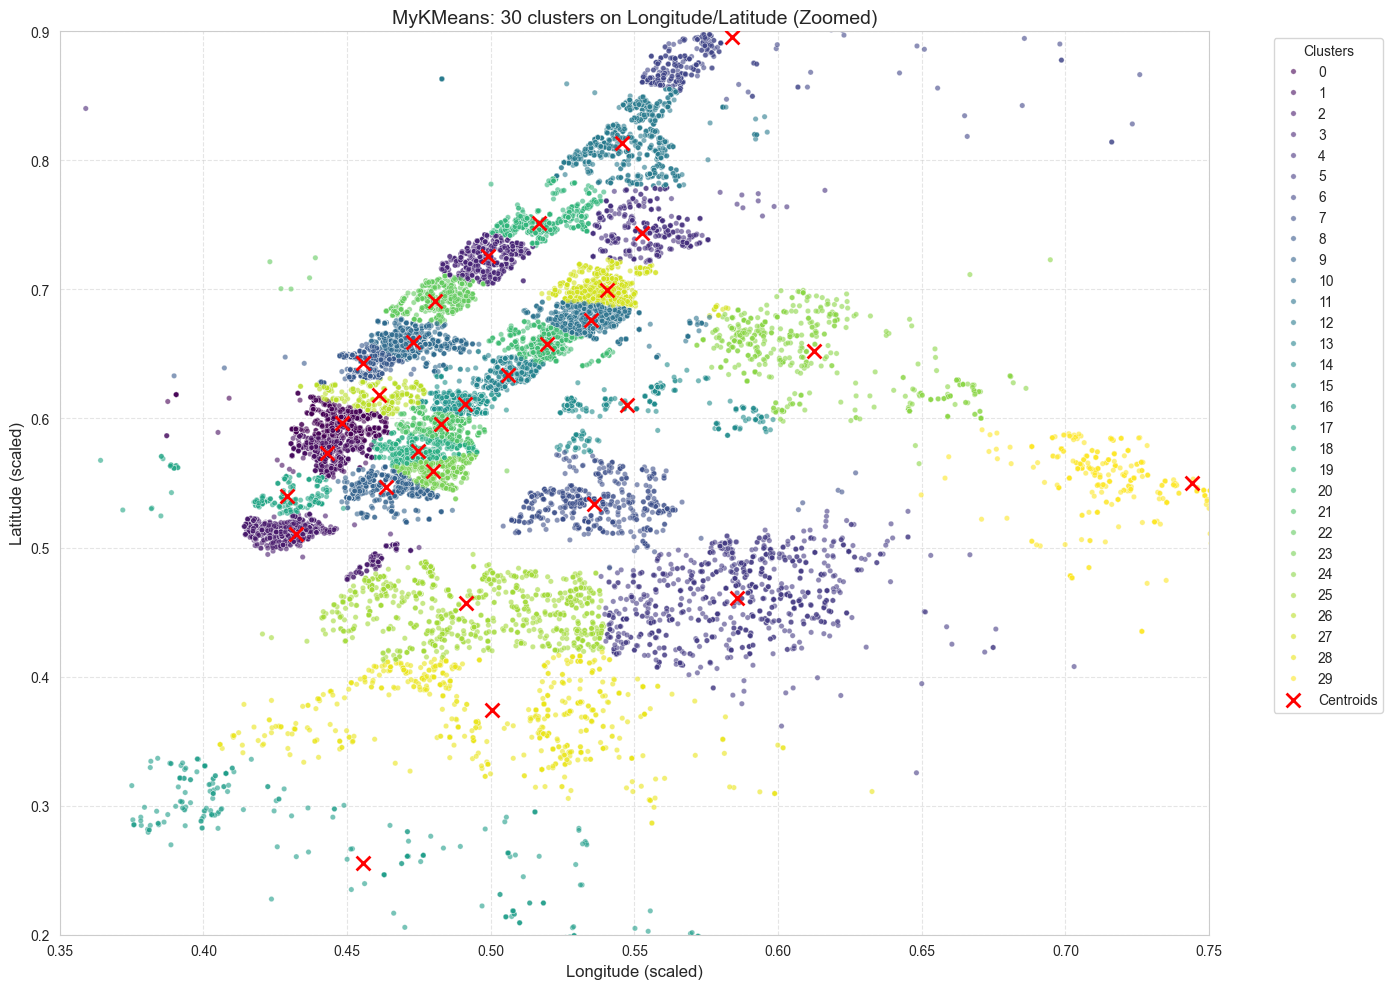

In [13]:
plt.figure(figsize=(14, 10))

sns.scatterplot(
    x=X_geo_scaled[:, 0], 
    y=X_geo_scaled[:, 1], 
    hue=my_kmeans.labels_, 
    palette='viridis',
    s=15,                 
    alpha=0.6,            
    legend='full' # Показать 30 кластеров в легенде
)

plt.scatter(
    my_kmeans.centroids_[:, 0], 
    my_kmeans.centroids_[:, 1], 
    c='red', 
    marker='x', 
    s=100, 
    linewidths=2,
    label='Centroids',
    zorder=5
)

#отсекание осей
plt.xlim(0.35, 0.75) 
plt.ylim(0.20, 0.90)

#bbox_to_anchor выносит легенду за пределы графика, чтобы она не мешала
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title='Clusters')

plt.title('MyKMeans: 30 clusters on Longitude/Latitude (Zoomed)', fontsize=14)
plt.xlabel('Longitude (scaled)', fontsize=12)
plt.ylabel('Latitude (scaled)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout() #чтобы легенда сбоку не обрезалась при сохранении
plt.show()

In [14]:
train['distance_to_ny'] = np.sqrt((train['latitude'] - 40.7128)**2 + (train['longitude'] + 74.0060)**2)

train['cluster_label'] = my_kmeans.labels_

features = ['bathrooms', 'bedrooms', 'price', 'distance_to_ny', 'cluster_label'] + list(feature_map)

X = train[features]
y = train['interest_level']

In [15]:
lasso_scaler = MinMaxScaler()
X_scaled = lasso_scaler.fit_transform(X)

print(X_scaled.shape)

(48289, 24)


In [16]:
# from sklearn.linear_model import LassoCV

# lasso_cv = LassoCV(cv=5, random_state=42)
# lasso_cv.fit(X_scaled, y)
# print(f'оптимальный alpha: {lasso_cv.alpha_:.4f}')

In [17]:
lasso = Lasso(alpha=0.0001, random_state=42)
lasso.fit(X_scaled, y)

importance_df = pd.DataFrame({
    'feature': features,
    'weight': lasso.coef_,
    'importance': np.abs(lasso.coef_)
}).sort_values(by='importance', ascending=False)

In [18]:
print("Топ-15 важных признаков по версии Lasso:")
display(importance_df.head(15))

Топ-15 важных признаков по версии Lasso:


,feature,weight,importance
2,price,-1.822717,1.822717
0,bathrooms,0.918896,0.918896
1,bedrooms,0.910533,0.910533
3,distance_to_ny,-0.429910,0.429910
11,NoFee,0.160707,0.160707
14,Pre-War,-0.078107,0.078107
6,HardwoodFloors,0.075995,0.075995
18,DiningRoom,0.063085,0.063085
9,Doorman,-0.053149,0.053149
19,HighSpeedInternet,0.049137,0.049137


In [19]:
display(importance_df[importance_df['feature'] == 'cluster_label'])

,feature,weight,importance
4,cluster_label,0.045074,0.045074


# Task 4

In [ ]:
from collections import deque

class MyDBSCAN:
    def __init__(self, eps=0.01, min_samples=10): #eps - радиус окрест-ти
        self.eps = eps
        self.min_samples = min_samples
        self.labels_ = None

    def fit(self, X):
        n_samples = X.shape[0]
        # -2: еще не посещали, -1: шум, 0+: номер кластера
        self.labels_ = np.full(n_samples, -2)
        cluster_id = 0

        def get_neighbors(point_idx):
            dists = np.linalg.norm(X - X[point_idx], axis=1) #расстояние от текущей точки до всех остальных
            return np.where(dists <= self.eps)[0]

        for i in range(n_samples):
            if self.labels_[i] != -2: 
                continue

            neighbors = get_neighbors(i)

            #если соседей меньше min_samples, это шум (пока что)
            if len(neighbors) < self.min_samples:
                self.labels_[i] = -1
            else:
                #создаем новый кластер
                self.labels_[i] = cluster_id
                queue = deque(neighbors)
                queue_set = set(neighbors)
                queue_set.discard(i) #меняем множ-во, но очередь остается такой же

                while queue:
                    current_point = queue.popleft() #убираем по первому эл-ту из мн-ва
                    
                    if self.labels_[current_point] == -1:#проверка на шум
                        self.labels_[current_point] = cluster_id
                        
                    if self.labels_[current_point] != -2: #не обр-но
                        continue
                        
                    self.labels_[current_point] = cluster_id
                    current_neighbors = get_neighbors(current_point)
                    
                    if len(current_neighbors) >= self.min_samples:
                        for n in current_neighbors:
                            if n not in queue_set:
                                queue.append(n)
                                queue_set.add(n)
                                
                cluster_id += 1
                
        return self

    def fit_predict(self, X):
        self.fit(X)
        return self.labels_

In [21]:
X_geo = train[['longitude', 'latitude']].values
scaler_geo = MinMaxScaler()
X_geo_scaled = scaler_geo.fit_transform(X_geo)

In [22]:
my_dbscan_best = MyDBSCAN(eps=0.01, min_samples=5)
labels_my = my_dbscan_best.fit_predict(X_geo_scaled)

In [23]:
sk_dbscan = DBSCAN(eps=0.01, min_samples=5)
labels_sk = sk_dbscan.fit_predict(X_geo_scaled)

In [24]:
n_clusters_my = len(set(labels_my)) - (1 if -1 in labels_my else 0)
n_noise_my = list(labels_my).count(-1)

n_clusters_sk = len(set(labels_sk)) - (1 if -1 in labels_sk else 0)
n_noise_sk = list(labels_sk).count(-1)

sil_my = silhouette_score(X_geo_scaled, labels_my) if n_clusters_my > 1 else -1
sil_sk = silhouette_score(X_geo_scaled, labels_sk) if n_clusters_sk > 1 else -1

In [25]:
match = np.mean(labels_my == labels_sk) * 100

comparison_db = pd.DataFrame({
    'Метрика': ['Кол-во кластеров', 'Кол-во шума', 'Silhouette', 'Совпадение меток (%)'],
    'MyDBSCAN': [n_clusters_my, n_noise_my, round(sil_my, 4),f"{match:.1f}%"],
    'Sklearn DBSCAN': [n_clusters_sk, n_noise_sk, round(sil_sk, 4),"100% (Эталон)"]
})

display(comparison_db)

,Метрика,MyDBSCAN,Sklearn DBSCAN
0,Кол-во кластеров,45,45
1,Кол-во шума,251,251
2,Silhouette,-0.1266,-0.1266
3,Совпадение меток (%),100.0%,100% (Эталон)


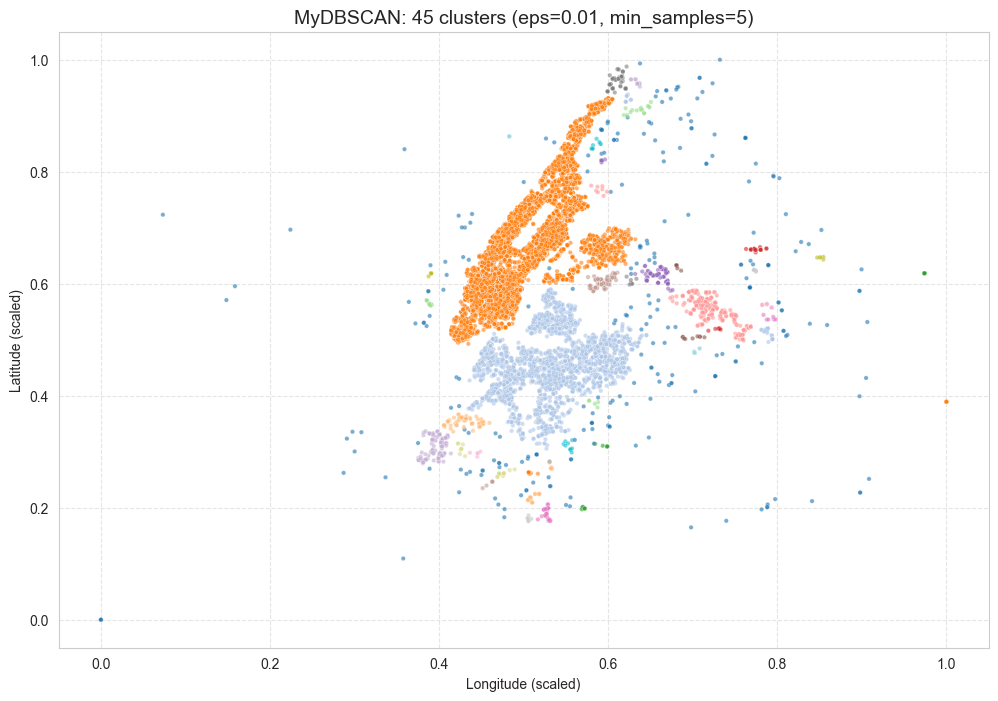

In [26]:
plt.figure(figsize=(12, 8))

sns.scatterplot(
    x=X_geo_scaled[:, 0], y=X_geo_scaled[:, 1], 
    hue=labels_my, palette='tab20', 
    s=10, alpha=0.6, legend=False
)

plt.title(f'MyDBSCAN: {n_clusters_my} clusters (eps=0.01, min_samples=5)', fontsize=14)
plt.xlabel('Longitude (scaled)')
plt.ylabel('Latitude (scaled)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [27]:
train['cluster_label'] = labels_my

features = ['bathrooms', 'bedrooms', 'price', 'distance_to_ny', 'cluster_label'] + list(feature_map)

X_db = train[features]
y_db = train['interest_level']

lasso_scaler_db = MinMaxScaler()
X_db_scaled = lasso_scaler_db.fit_transform(X_db)

In [28]:
lasso_db = Lasso(alpha=0.0001, random_state=42)
lasso_db.fit(X_db_scaled, y_db)

importance_db = pd.DataFrame({
    'feature': features,
    'importance': np.abs(lasso_db.coef_)
}).sort_values(by='importance', ascending=False)

In [29]:
print("Топ-10 важных признаков (DBSCAN):")
display(importance_db.head(10))

Топ-10 важных признаков (DBSCAN):


,feature,importance
2,price,1.811038
0,bathrooms,0.924584
1,bedrooms,0.908145
4,cluster_label,0.517944
3,distance_to_ny,0.467444
11,NoFee,0.161797
14,Pre-War,0.078463
6,HardwoodFloors,0.075983
18,DiningRoom,0.062367
9,Doorman,0.054172


In [30]:
# eps_list = [0.005, 0.01, 0.02]
# min_samples_list = [5, 10, 20]
# results = []

# for eps in eps_list:
#     for ms in min_samples_list:
#         db = MyDBSCAN(eps=eps, min_samples=ms)
#         labels_tmp = db.fit_predict(X_geo_scaled)
        
#         if len(set(labels_tmp)) - (1 if -1 in labels_tmp else 0) > 1:
#             train['tmp_cluster'] = labels_tmp
#             feats_tmp = ['bathrooms', 'bedrooms', 'price', 'distance_to_ny', 'tmp_cluster'] + list(feature_map)
            
#             X_tmp = lasso_scaler_db.fit_transform(train[feats_tmp])
#             y_tmp = train['interest_level']
            
#             l_tmp = Lasso(alpha=0.0001, random_state=42)
#             l_tmp.fit(X_tmp, y_tmp)
            
#             r2 = r2_score(y_tmp, l_tmp.predict(X_tmp))
#             results.append({'eps': eps, 'min_samples': ms, 'r2_score': r2})

# display(pd.DataFrame(results).sort_values(by='r2_score', ascending=False))

# Task 5

In [31]:
agg_model = AgglomerativeClustering(n_clusters=30)
labels_agg = agg_model.fit_predict(X_geo_scaled)

sil_agg = silhouette_score(X_geo_scaled, labels_agg)

print(f"Agglomerative Silhouette: {sil_agg:.4f}")

Agglomerative Silhouette: 0.4344


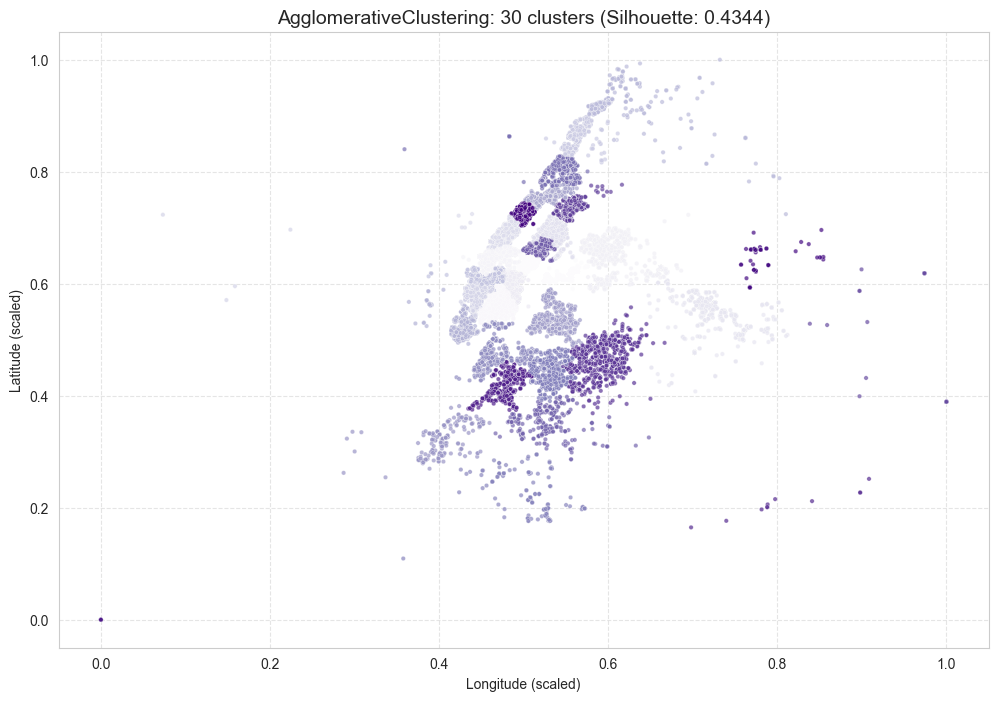

In [32]:
plt.figure(figsize=(12, 8))

sns.scatterplot(
    x=X_geo_scaled[:, 0], 
    y=X_geo_scaled[:, 1], 
    hue=labels_agg, 
    palette='Purples', 
    s=10, 
    alpha=0.7, 
    legend=False
)

plt.title(f'AgglomerativeClustering: 30 clusters (Silhouette: {sil_agg:.4f})', fontsize=14)
plt.xlabel('Longitude (scaled)')
plt.ylabel('Latitude (scaled)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [33]:
train['cluster_label'] = labels_agg

features = ['bathrooms', 'bedrooms', 'price', 'distance_to_ny', 'cluster_label'] + list(feature_map)

X_agg = train[features]
y_agg = train['interest_level']

In [34]:
lasso_scaler_agg = MinMaxScaler()
X_agg_scaled = lasso_scaler_agg.fit_transform(X_agg)

lasso_agg = Lasso(alpha=0.0001, random_state=42)
lasso_agg.fit(X_agg_scaled, y_agg)

,alpha,0.0001
,fit_intercept,True
,precompute,False
,copy_X,True
,max_iter,1000
,tol,0.0001
,warm_start,False
,positive,False
,random_state,42
,selection,'cyclic'


In [35]:
importance_agg = pd.DataFrame({
    'feature': features,
    'importance': np.abs(lasso_agg.coef_)
}).sort_values(by='importance', ascending=False)

print("Топ-10 важных признаков (Agglomerative):")
display(importance_agg.head(10))

print("\nПозиция cluster_label:")
display(importance_agg[importance_agg['feature'] == 'cluster_label'])

Топ-10 важных признаков (Agglomerative):


,feature,importance
2,price,1.823460
0,bathrooms,0.938908
1,bedrooms,0.913617
3,distance_to_ny,0.374204
11,NoFee,0.160975
14,Pre-War,0.077998
6,HardwoodFloors,0.074142
18,DiningRoom,0.062668
9,Doorman,0.054912
19,HighSpeedInternet,0.048273



Позиция cluster_label:


,feature,importance
4,cluster_label,0.04727


# Task 6

In [36]:
gmm_model = GaussianMixture(n_components=30, random_state=42)
labels_gmm = gmm_model.fit_predict(X_geo_scaled)

sil_gmm = silhouette_score(X_geo_scaled, labels_gmm)
print(f"GaussianMixture Silhouette: {sil_gmm:.4f}")

GaussianMixture Silhouette: 0.3559


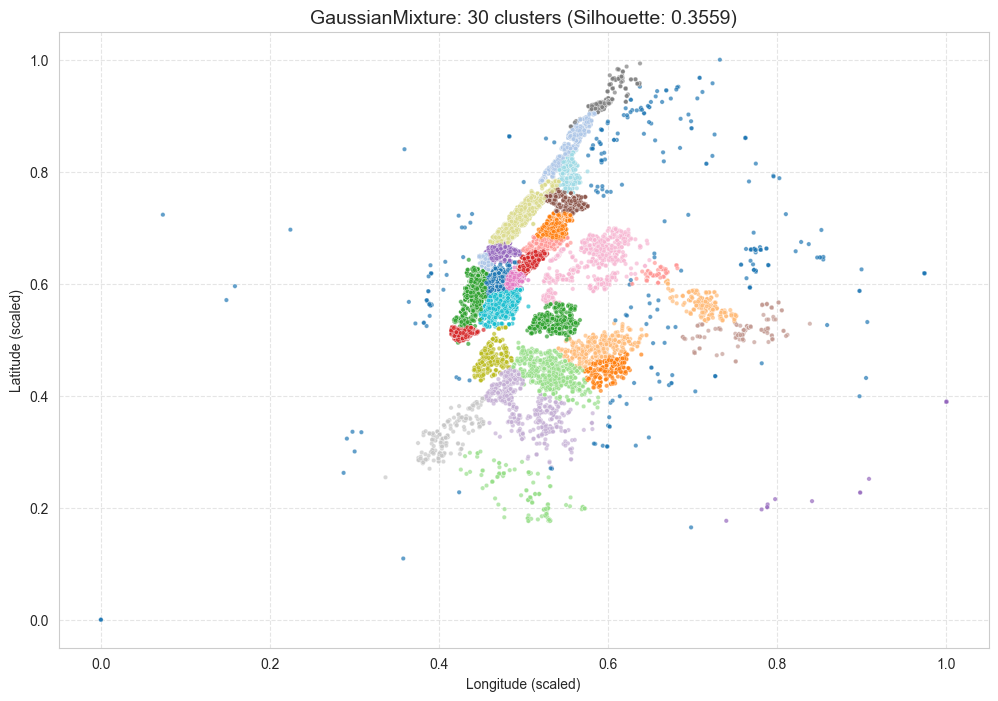

In [37]:
plt.figure(figsize=(12, 8))

sns.scatterplot(
    x=X_geo_scaled[:, 0], 
    y=X_geo_scaled[:, 1], 
    hue=labels_gmm, 
    palette='tab20', 
    s=10, 
    alpha=0.7, 
    legend=False
)

plt.title(f'GaussianMixture: 30 clusters (Silhouette: {sil_gmm:.4f})', fontsize=14)
plt.xlabel('Longitude (scaled)')
plt.ylabel('Latitude (scaled)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [38]:
train['cluster_label'] = labels_gmm

features = ['bathrooms', 'bedrooms', 'price', 'distance_to_ny', 'cluster_label'] + list(feature_map)
X_gmm = train[features]
y_gmm = train['interest_level']

In [39]:
lasso_scaler_gmm = MinMaxScaler()
X_gmm_scaled = lasso_scaler_gmm.fit_transform(X_gmm)

lasso_gmm = Lasso(alpha=0.0001, random_state=42)
lasso_gmm.fit(X_gmm_scaled, y_gmm)

,alpha,0.0001
,fit_intercept,True
,precompute,False
,copy_X,True
,max_iter,1000
,tol,0.0001
,warm_start,False
,positive,False
,random_state,42
,selection,'cyclic'


In [51]:
importance_gmm = pd.DataFrame({
    'feature': features,
    'importance': np.abs(lasso_gmm.coef_)
}).sort_values(by='importance', ascending=False)

print("Топ-10 важных признаков (GMM):")
display(importance_gmm.head(15))

print("\nПозиция cluster_label:")
display(importance_gmm[importance_gmm['feature'] == 'cluster_label'])

Топ-10 важных признаков (GMM):


,feature,importance
2,price,1.818597
0,bathrooms,0.925033
1,bedrooms,0.908147
3,distance_to_ny,0.403920
11,NoFee,0.159458
14,Pre-War,0.078086
6,HardwoodFloors,0.076057
18,DiningRoom,0.064445
9,Doorman,0.054762
19,HighSpeedInternet,0.048893



Позиция cluster_label:


,feature,importance
4,cluster_label,0.0


# Task 7

In [41]:
features_3d = ['bedrooms', 'bathrooms', 'interest_level']
X_3d = train[features_3d].values

scaler_3d = MinMaxScaler()
X_3d_scaled = scaler_3d.fit_transform(X_3d)

results_3d = []

In [42]:
kmeans_3d = KMeans(n_clusters=5, random_state=42, n_init=10)
labels_km = kmeans_3d.fit_predict(X_3d_scaled)
sil_km = silhouette_score(X_3d_scaled, labels_km)
results_3d.append({'Алгоритм': 'K-Means (5)', 'Silhouette': round(sil_km, 4), 'Кластеров': len(set(labels_km))})

In [43]:
gmm_3d = GaussianMixture(n_components=5, random_state=42)
labels_gmm = gmm_3d.fit_predict(X_3d_scaled)
sil_gmm = silhouette_score(X_3d_scaled, labels_gmm)
results_3d.append({'Алгоритм': 'GMM (5)', 'Silhouette': round(sil_gmm, 4), 'Кластеров': len(set(labels_gmm))})

In [44]:
agg_3d = AgglomerativeClustering(n_clusters=5)
labels_agg = agg_3d.fit_predict(X_3d_scaled)
sil_agg = silhouette_score(X_3d_scaled, labels_agg)
results_3d.append({'Алгоритм': 'Agglomerative (5)', 'Silhouette': round(sil_agg, 4), 'Кластеров': len(set(labels_agg))})

In [45]:
db_3d = DBSCAN(eps=0.1, min_samples=5)
labels_db = db_3d.fit_predict(X_3d_scaled)
#нашел ли DBSCAN хотя бы 2 кластера (иначе Silhouette не считается)
n_cl = len(set(labels_db)) - (1 if -1 in labels_db else 0)
sil_db = silhouette_score(X_3d_scaled, labels_db) if n_cl > 1 else -1
results_3d.append({'Алгоритм': 'DBSCAN (eps=0.1)', 'Silhouette': round(sil_db, 4), 'Кластеров': n_cl})

In [46]:
display(pd.DataFrame(results_3d))

,Алгоритм,Silhouette,Кластеров
0,K-Means (5),0.6405,5
1,GMM (5),0.4395,5
2,Agglomerative (5),0.6396,5
3,DBSCAN (eps=0.1),0.8214,18


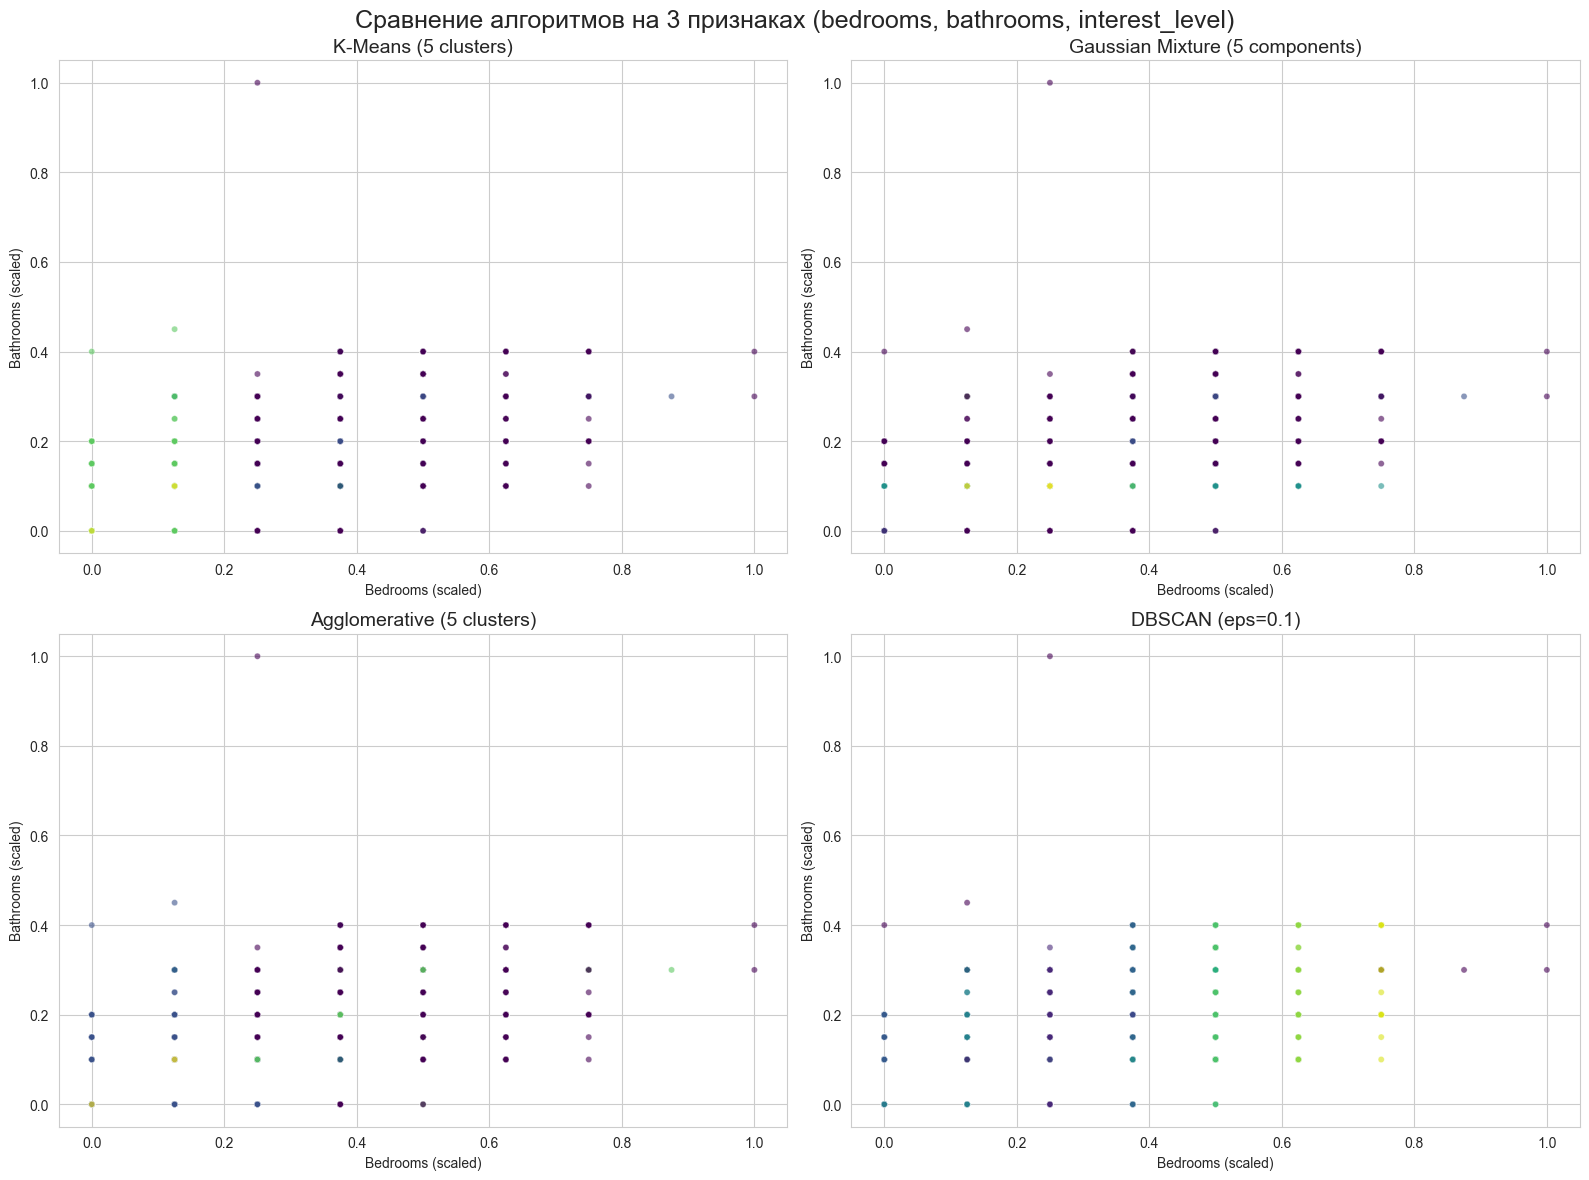

In [47]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

#K-Means
sns.scatterplot(x=X_3d_scaled[:, 0], y=X_3d_scaled[:, 1], hue=labels_km, 
                palette='viridis', s=20, alpha=0.6, ax=axes[0], legend=False)
axes[0].set_title('K-Means (5 clusters)', fontsize=14)
axes[0].set_xlabel('Bedrooms (scaled)')
axes[0].set_ylabel('Bathrooms (scaled)')

#GMM
sns.scatterplot(x=X_3d_scaled[:, 0], y=X_3d_scaled[:, 1], hue=labels_gmm, 
                palette='viridis', s=20, alpha=0.6, ax=axes[1], legend=False)
axes[1].set_title('Gaussian Mixture (5 components)', fontsize=14)
axes[1].set_xlabel('Bedrooms (scaled)')
axes[1].set_ylabel('Bathrooms (scaled)')

#Agglomerative
sns.scatterplot(x=X_3d_scaled[:, 0], y=X_3d_scaled[:, 1], hue=labels_agg, 
                palette='viridis', s=20, alpha=0.6, ax=axes[2], legend=False)
axes[2].set_title('Agglomerative (5 clusters)', fontsize=14)
axes[2].set_xlabel('Bedrooms (scaled)')
axes[2].set_ylabel('Bathrooms (scaled)')

#DBSCAN (здесь шум -1 тоже получит свой цвет)
sns.scatterplot(x=X_3d_scaled[:, 0], y=X_3d_scaled[:, 1], hue=labels_db, 
                palette='viridis', s=20, alpha=0.6, ax=axes[3], legend=False)
axes[3].set_title('DBSCAN (eps=0.1)', fontsize=14)
axes[3].set_xlabel('Bedrooms (scaled)')
axes[3].set_ylabel('Bathrooms (scaled)')

plt.suptitle('Сравнение алгоритмов на 3 признаках (bedrooms, bathrooms, interest_level)', fontsize=18)
plt.tight_layout()
plt.show()

In [62]:
algorithms_3d = {
    'K-Means': labels_km,
    'GMM': labels_gmm,
    'Agglomerative': labels_agg,
    'DBSCAN': labels_db
}

features_3d_lasso = ['bathrooms', 'bedrooms', 'price'] + list(feature_map)
y_3d = train['interest_level']

# features_3d_lasso = ['bathrooms', 'bedrooms', 'interest_level'] + list(feature_map)
# y_3d = train['price']

In [63]:
results_importance_3d = {}

for name, labels in algorithms_3d.items():
    train['cluster_label_3d'] = labels
    
    X_3d = train[features_3d_lasso + ['cluster_label_3d']]
    
    scaler = MinMaxScaler()
    X_3d_scaled = scaler.fit_transform(X_3d)
    
    lasso_3d = Lasso(alpha=0.0001, random_state=42)
    lasso_3d.fit(X_3d_scaled, y_3d)
    
    imp_df = pd.DataFrame({
        'feature': X_3d.columns,
        'importance': np.abs(lasso_3d.coef_)
    }).sort_values(by='importance', ascending=False)
    
    results_importance_3d[name] = imp_df


In [64]:
for name, df in results_importance_3d.items():
    print(f"\n--- {name} (3 features) ---")
    display(df.head(10))


--- K-Means (3 features) ---


,feature,importance
1,bedrooms,2.409117
2,price,1.509494
22,cluster_label_3d,0.790715
0,bathrooms,0.764153
9,NoFee,0.143384
12,Pre-War,0.076747
4,HardwoodFloors,0.073580
16,DiningRoom,0.051927
17,HighSpeedInternet,0.047128
15,OutdoorSpace,0.041563



--- GMM (3 features) ---


,feature,importance
0,bathrooms,6.927698
22,cluster_label_3d,1.806520
2,price,0.646734
1,bedrooms,0.545298
9,NoFee,0.078373
12,Pre-War,0.058610
16,DiningRoom,0.045609
6,DogsAllowed,0.034396
15,OutdoorSpace,0.031085
17,HighSpeedInternet,0.029236



--- Agglomerative (3 features) ---


,feature,importance
22,cluster_label_3d,1.403004
1,bedrooms,1.258536
2,price,0.622175
0,bathrooms,0.376455
9,NoFee,0.062221
12,Pre-War,0.039669
16,DiningRoom,0.029517
17,HighSpeedInternet,0.019771
15,OutdoorSpace,0.018110
7,Doorman,0.017792



--- DBSCAN (3 features) ---


,feature,importance
2,price,1.630942
1,bedrooms,0.811724
22,cluster_label_3d,0.698087
0,bathrooms,0.549907
9,NoFee,0.153244
4,HardwoodFloors,0.086446
12,Pre-War,0.075504
16,DiningRoom,0.052496
7,Doorman,0.042241
15,OutdoorSpace,0.040644


# Task 8

In [65]:
geo_results = pd.DataFrame({
    'Algorithm': ['K-Means', 'DBSCAN', 'Agglomerative', 'GMM'],
    'Features': ['Geo (lon/lat)'] * 4,
    'Time (approx)': ['~40 sec', '~3 min', '~14 min', '~45 sec'],
    'Silhouette': [sil, sil_db, sil_agg, sil_gmm],
    'Clusters Found': [30, 45, 30, 30]
})

In [66]:
d3_results = pd.DataFrame({
    'Algorithm': ['K-Means', 'GMM', 'Agglomerative', 'DBSCAN'],
    'Features': ['3D (beds/baths/interest)'] * 4,
    'Time (approx)': ['39 sec', '44 sec', '3m 50s', '37 sec'],
    'Silhouette': [sil_km, sil_gmm, sil_agg, sil_db],
    'Clusters Found': [5, 5, 5, 18]
})

In [50]:
final_comparison = pd.concat([geo_results, d3_results], ignore_index=True)

display(final_comparison)

,Algorithm,Features,Time (approx),Silhouette,Clusters Found
0,K-Means,Geo (lon/lat),~40 sec,0.421338,30
1,DBSCAN,Geo (lon/lat),~3 min,0.821370,45
2,Agglomerative,Geo (lon/lat),~14 min,0.639641,30
3,GMM,Geo (lon/lat),~45 sec,0.439515,30
4,K-Means,3D (beds/baths/interest),39 sec,0.640461,5
5,GMM,3D (beds/baths/interest),44 sec,0.439515,5
6,Agglomerative,3D (beds/baths/interest),3m 50s,0.639641,5
7,DBSCAN,3D (beds/baths/interest),37 sec,0.821370,18
